# 06 - Advisory and End-to-End Demo

**Goal:** run the full farmer-facing flow on real test leaves: *photo -> quality gate -> FP32 model -> confidence threshold -> advisory -> Grad-CAM*.

Everything here calls `scripts/inference_utils.py`, the same module the Streamlit app uses, so the notebook and the app cannot disagree.

Run notebook 05 first: it calibrates the gate and the confidence threshold that this notebook loads. If its outputs are missing, provisional defaults are used and the notebook says so.

**Scope reminder:** this is decision support for 15 classes of Potato, Tomato and Pepper leaves, not a diagnosis.

In [1]:
# Cell 1 - locate the repo root and make the existing scripts importable
import os, sys, json, math, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = Path.cwd().resolve()
while not (ROOT / 'manifest.csv').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'manifest.csv').exists(), 'Open this notebook from inside the repo (manifest.csv not found)'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'scripts'))
print('[setup] repo root :', ROOT)

[setup] repo root : C:\Users\amit0\OneDrive\Documents\plant_disease_detection


In [2]:
# Cell 2 - imports
import numpy as np
import pandas as pd
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import data_pipeline as dp
import inference_utils as iu
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
SEED = 42
print('[versions] TF', tf.__version__, '| pandas', pd.__version__)

[versions] TF 2.21.0 | pandas 2.2.3


## 1. Load the artifacts and validate the advisory table

In [3]:
# Cell 3 - model, advisory table (validated against the model's class list), gate config, threshold
model = tf.keras.models.load_model('best_model.keras')
advisory = iu.load_advisory()
problems = iu.validate_advisory(advisory)
print('[advisory] rows:', len(advisory), '| validation problems:', problems)
assert not problems, problems
gate_cfg = iu.GateConfig.load()
gate_src = 'calibrated file' if os.path.exists(iu.GATE_CONFIG_PATH) else 'provisional defaults (run notebook 05 to calibrate)'
print('[gate] source:', gate_src)
print('[gate] config:', gate_cfg)
report_path = ROOT / 'advisory' / 'safeguards_report.json'
if report_path.exists():
    THRESHOLD = json.load(open(report_path))['threshold']
    print('[threshold] loaded from safeguards_report.json:', THRESHOLD)
else:
    THRESHOLD = 0.80
    print('[threshold] safeguards_report.json not found; using provisional', THRESHOLD)

[advisory] rows: 15 | validation problems: []
[gate] source: calibrated file
[gate] config: GateConfig(min_side=100, min_sharpness=44.75270565032959, max_noise_sigma=19.09115822443941, min_brightness=23.4725161895752, max_brightness=174.5506338500977)
[threshold] loaded from safeguards_report.json: 0.3


In [4]:
# Cell 4 - what the advisory table contains (pandas overview) and how much of it is verified
print(advisory.groupby('category').size().sort_values(ascending=False))
print(pd.crosstab(advisory['crop'], advisory['category']))
print(advisory['source_status'].value_counts())
unreviewed = int((advisory['source_status'] != 'reviewed').sum())
print('[advisory] entries whose guidance has NOT yet been checked against its source:', unreviewed, 'of', len(advisory))

category
fungal       5
healthy      3
bacterial    2
oomycete     2
viral        2
pest         1
dtype: int64
category  bacterial  fungal  healthy  oomycete  pest  viral
crop                                                       
Pepper            1       0        1         0     0      0
Potato            0       1        1         1     0      0
Tomato            1       4        1         1     1      2
source_status
url_found_content_unreviewed    8
general_guidance_unreviewed     7
Name: count, dtype: int64
[advisory] entries whose guidance has NOT yet been checked against its source: 15 of 15


## 2. Run the full pipeline on one real test leaf per class

In [5]:
# Cell 5 - pick one test-split image per class (only images present on this machine)
def _can_read(p):
    try:
        with open(p, 'rb') as f:
            return len(f.read(1)) == 1
    except OSError:
        return False
manifest = pd.read_csv('manifest.csv')
manifest['File_Path'] = manifest['File_Path'].str.replace(chr(92), '/', regex=False)
manifest = manifest[manifest['File_Path'].map(_can_read)]
manifest = manifest[manifest['File_Path'].map(os.path.exists)]
samples = (manifest[manifest['split'] == 'test'].sample(frac=1, random_state=SEED)
           .groupby('Class_Name').head(1).reset_index(drop=True))
print('[samples] one test image per class, images found on disk:', len(samples))
assert len(samples) > 0

[samples] one test image per class, images found on disk: 15


In [6]:
# Cell 6 - analyse each leaf with the shared pipeline and tabulate the outcome
results = []
for r in samples.itertuples():
    res = iu.analyze_image(model, r.File_Path, advisory=advisory, cfg=gate_cfg, threshold=THRESHOLD)
    results.append((r, res))
rows = []
for r, res in results:
    adv = res.get('advisory', {})
    rows.append({'true_class': r.Class_Name, 'status': res['status'], 'predicted': res.get('label'),
                 'confidence': res.get('confidence'), 'category': adv.get('category'),
                 'is_healthy': adv.get('is_healthy'), 'correct': res.get('label') == r.Class_Name})
table = pd.DataFrame(rows)
print(table.round(3).to_string(index=False))
print(table['status'].value_counts())
answered = table[table['status'] == 'ok']
print('[demo] accuracy on answered images:', round(answered['correct'].mean(), 3), 'of', len(answered))

                                 true_class status                                   predicted  confidence  category  is_healthy  correct
                Tomato__Tomato_mosaic_virus     ok                 Tomato__Tomato_mosaic_virus       0.983     viral       False     True
                           Tomato_Leaf_Mold     ok                            Tomato_Leaf_Mold       0.999    fungal       False     True
      Tomato__Tomato_YellowLeaf__Curl_Virus     ok       Tomato__Tomato_YellowLeaf__Curl_Virus       0.999     viral       False     True
                             Tomato_healthy     ok                              Tomato_healthy       0.997   healthy        True     True
                     Pepper__bell___healthy     ok                      Pepper__bell___healthy       0.993   healthy        True     True
                  Tomato_Septoria_leaf_spot     ok                   Tomato_Septoria_leaf_spot       0.759    fungal       False     True
                        Tomato__Ta

## 3. Grad-CAM: does the heat sit on the leaf?

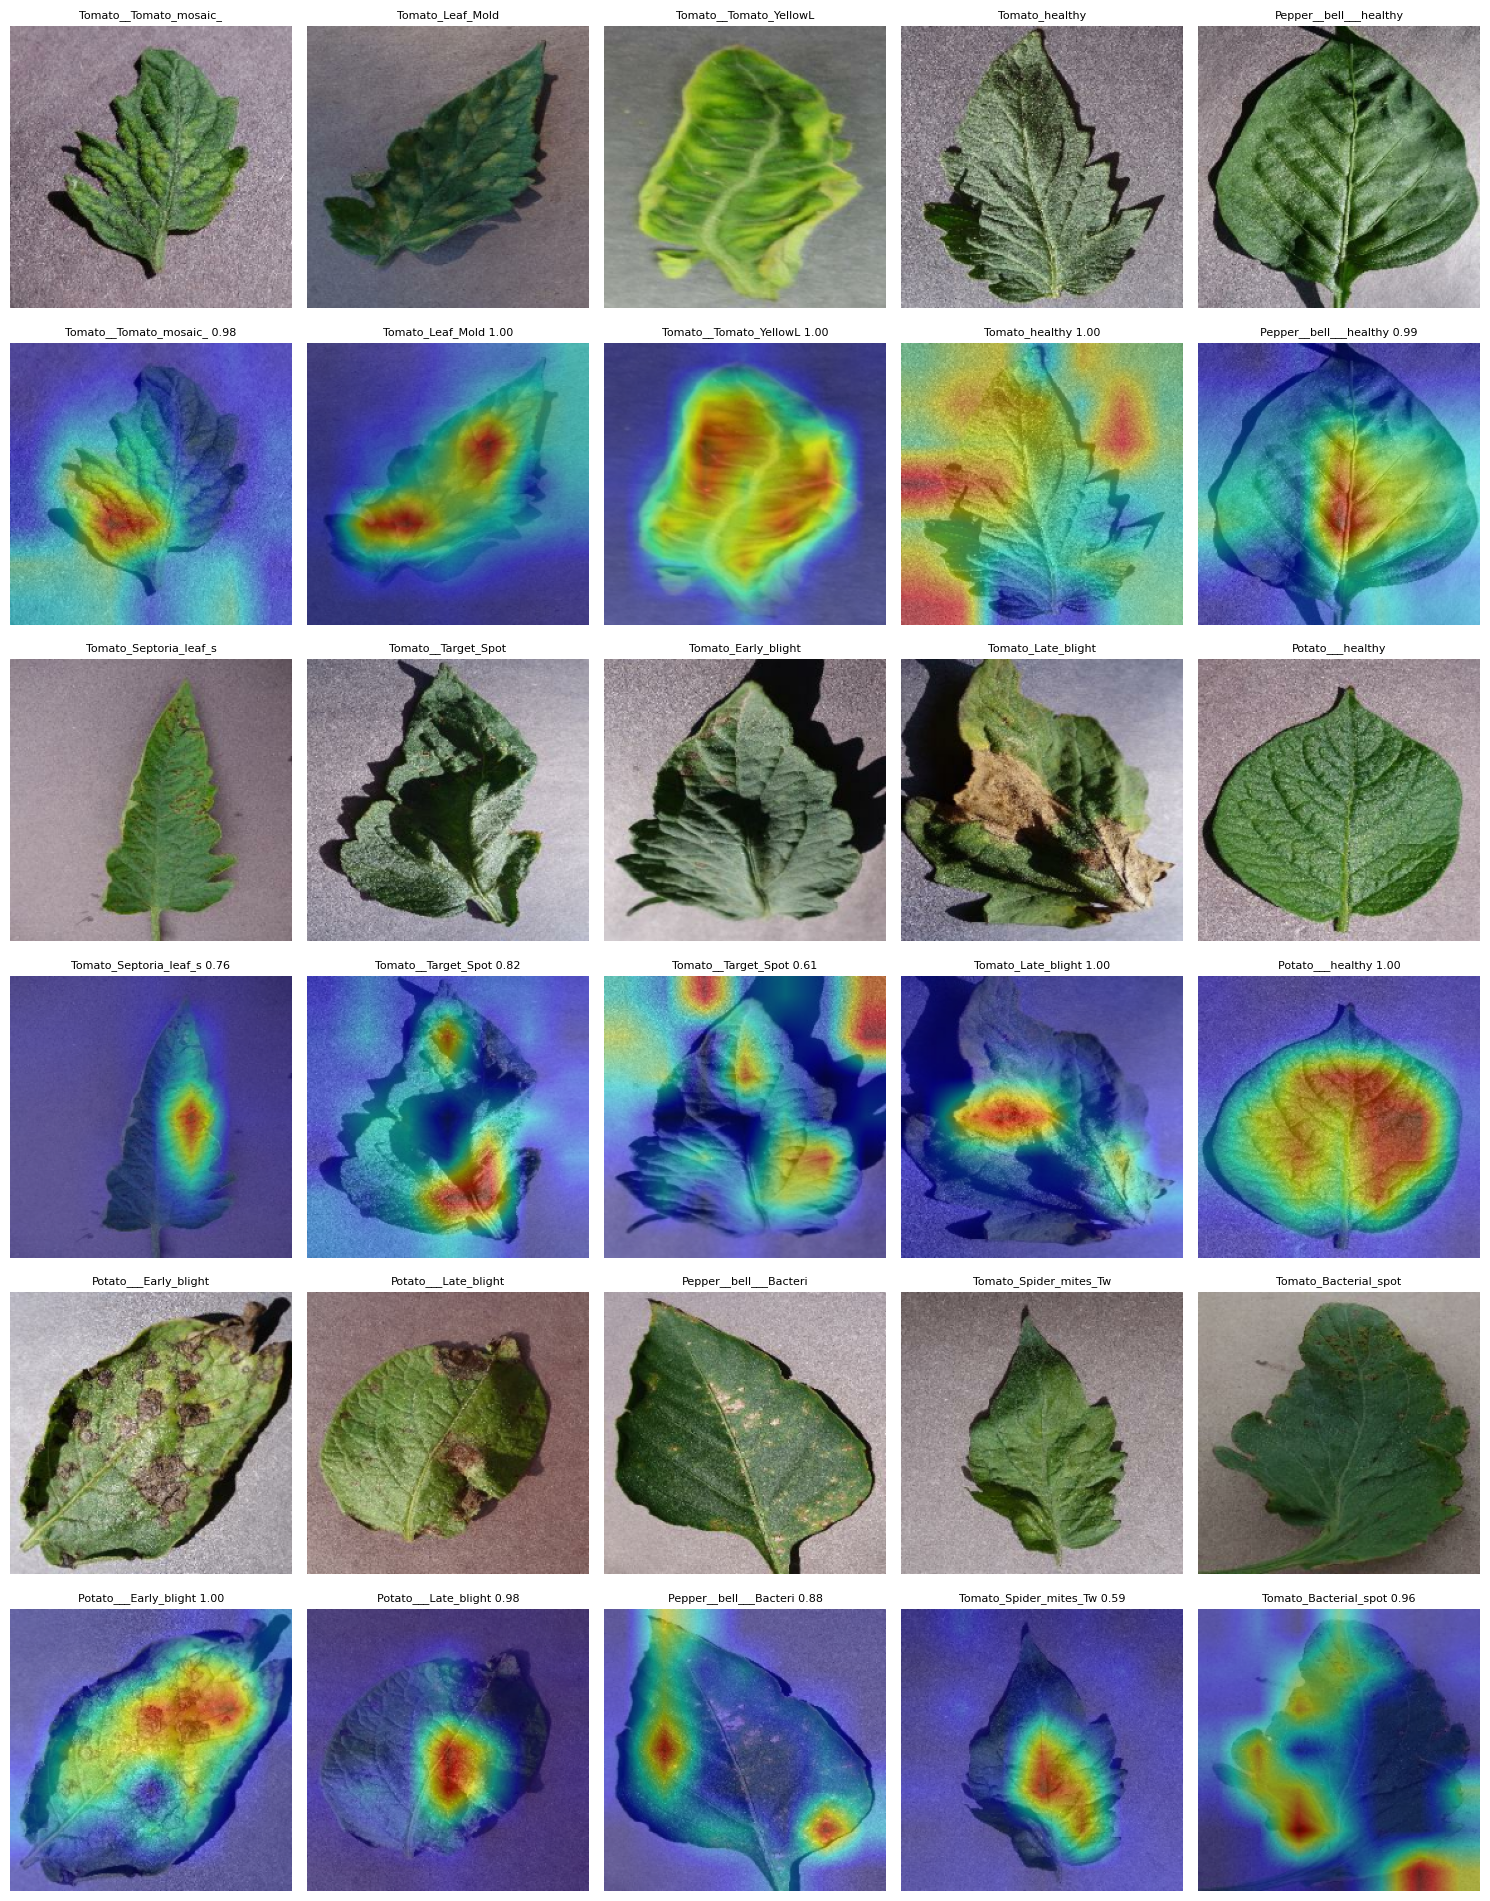

[saved] C:\Users\amit0\OneDrive\Documents\plant_disease_detection\advisory\demo_gradcam_grid.png


In [7]:
# Cell 7 - originals on the top row of each pair, Grad-CAM overlays underneath
n = len(results)
cols = 5
groups = math.ceil(n / cols)
fig, axes = plt.subplots(groups * 2, cols, figsize=(3 * cols, 3.2 * groups * 2))
axes = np.atleast_2d(axes)
for ax in axes.ravel():
    ax.axis('off')
for k, (r, res) in enumerate(results):
    g, c = divmod(k, cols)
    rgb = iu._as_uint8(iu.resize_for_model(iu.to_uint8_rgb(r.File_Path)))
    axes[2 * g, c].imshow(rgb)
    axes[2 * g, c].set_title(r.Class_Name[:22], fontsize=8)
    if 'overlay' in res:
        title = res['label'][:22] + ' ' + format(res['confidence'], '.2f')
        axes[2 * g + 1, c].imshow(res['overlay'])
        axes[2 * g + 1, c].set_title(title, fontsize=8)
plt.tight_layout()
grid_path = ROOT / 'advisory' / 'demo_gradcam_grid.png'
plt.savefig(grid_path, dpi=80)
plt.show()
print('[saved]', grid_path)

In [8]:
# Cell 8 - a rough numeric check of the overlays: share of Grad-CAM heat that falls on the leaf
def leaf_attention(rgb224, heatmap):
    big = cv2.resize(heatmap.astype(np.float32), (224, 224))
    border = np.concatenate([rgb224[:6].reshape(-1, 3), rgb224[-6:].reshape(-1, 3)])
    bg = np.median(border, axis=0)
    mask = np.abs(rgb224.astype(int) - bg).sum(axis=-1) > 60
    return float(big[mask].sum() / (big.sum() + 1e-8)), float(mask.mean())
att_rows = []
for r, res in results:
    if 'heatmap' not in res:
        continue
    rgb = iu._as_uint8(iu.resize_for_model(iu.to_uint8_rgb(r.File_Path)))
    on_leaf, leaf_share = leaf_attention(rgb, res['heatmap'])
    att_rows.append({'class': r.Class_Name, 'heat_on_leaf': on_leaf, 'leaf_share_of_image': leaf_share})
attention = pd.DataFrame(att_rows).sort_values('heat_on_leaf')
print(attention.round(2).to_string(index=False))
print('[grad-cam] mean share of heat on the leaf:', round(attention['heat_on_leaf'].mean(), 2))
print('[grad-cam] images with under 50% of heat on the leaf:', int((attention['heat_on_leaf'] < 0.5).sum()))
print('[note] crude proxy: leaf = pixels unlike the border colour; it supports, not replaces, looking at the overlays')

                                      class  heat_on_leaf  leaf_share_of_image
                             Tomato_healthy          0.51                 0.53
                Tomato__Tomato_mosaic_virus          0.56                 0.47
                           Tomato_Leaf_Mold          0.69                 0.41
                        Tomato__Target_Spot          0.69                 0.68
                        Tomato_Early_blight          0.73                 0.74
              Pepper__bell___Bacterial_spot          0.78                 0.58
                       Potato___Late_blight          0.79                 0.50
Tomato_Spider_mites_Two_spotted_spider_mite          0.83                 0.67
                     Pepper__bell___healthy          0.84                 0.77
                  Tomato_Septoria_leaf_spot          0.84                 0.56
                      Tomato_Bacterial_spot          0.87                 0.82
                           Potato___healthy         

## 4. The farmer-facing report

In [9]:
# Cell 9 - render one plain-language report from the pipeline output
def render_report(res):
    lines = ['=' * 60]
    if res['status'] == 'rejected_quality':
        lines.append('RESULT : photo rejected')
        lines.append(res['message'])
    else:
        lines.append('RESULT : ' + res['status'].upper() + ' | ' + res['label'] + ' | confidence ' + format(res['confidence'], '.1%'))
        lines.append('TOP 3  : ' + ', '.join(c + ' ' + format(p, '.2f') for c, p in res['top3']))
        adv = res['advisory']
        lines.append('CROP   : ' + str(adv['crop']) + ' | CONDITION: ' + str(adv['condition']) + ' | TYPE: ' + str(adv['category']))
        lines.append('CAUSE  : ' + str(adv['cause']))
        lines.append('NOW    : ' + str(adv['what_to_do_now']))
        lines.append('PREVENT: ' + str(adv['prevention']))
        lines.append('SEEK HELP: ' + str(adv['when_to_seek_help']))
    lines.append('NOTE   : ' + res['disclaimer'])
    lines.append('=' * 60)
    return chr(10).join(lines)
diseased = [res for r, res in results if res['status'] == 'ok' and not res['advisory']['is_healthy']]
print(render_report(diseased[0] if diseased else results[0][1]))

RESULT : OK | Tomato__Tomato_mosaic_virus | confidence 98.3%
TOP 3  : Tomato__Tomato_mosaic_virus 0.98, Tomato_Leaf_Mold 0.01, Tomato_Late_blight 0.00
CROP   : Tomato | CONDITION: Tomato mosaic virus | TYPE: viral
CAUSE  : A virus that spreads on hands, tools and seed; leaves show mottled light and dark green patches and may be distorted. There is no cure.
NOW    : Remove and destroy infected plants; wash hands and clean tools after handling them; do not handle healthy plants after infected ones.
PREVENT: Use clean seed and resistant varieties; sanitise tools; avoid handling tobacco before touching plants.
SEEK HELP: As soon as symptoms appear, so the virus does not spread. Ask the extension office for local advice.
NOTE   : Decision support only, not a diagnosis. The model knows 15 classes of Potato, Tomato and Pepper leaves from lab-style photos. Confirm with a local agriculture extension officer before spraying or removing crops.


## 5. Failure modes: what the system does with bad input

In [10]:
# Cell 10 - degraded photos, a thumbnail, and two images that are not leaves at all
base = iu.to_uint8_rgb(samples.loc[0, 'File_Path'])
r224 = iu._as_uint8(iu.resize_for_model(base))
yy, xx = np.mgrid[0:300, 0:300]
gradient = np.stack([xx * 255 // 299, yy * 255 // 299, np.full((300, 300), 120)], axis=-1).astype(np.uint8)
texture = cv2.GaussianBlur(np.random.default_rng(0).integers(0, 255, (300, 300, 3)).astype(np.uint8), (0, 0), 2)
scenarios = {
    'clean leaf': base,
    'heavy noise (sigma 45)': iu.corrupt_image(r224, noise_sigma=45),
    'very blurry (motion 15)': iu.corrupt_image(r224, blur_len=15),
    'very dark (-100)': iu.corrupt_image(r224, brightness_delta=-100),
    'tiny thumbnail (60 px)': cv2.resize(base, (60, 60)),
    'not a leaf: gradient': gradient,
    'not a leaf: random texture': texture,
}
rows = []
for name, img in scenarios.items():
    res = iu.analyze_image(model, img, advisory=advisory, cfg=gate_cfg, threshold=THRESHOLD, with_gradcam=False)
    rows.append({'scenario': name, 'status': res['status'], 'label': res.get('label'),
                 'confidence': res.get('confidence'), 'message': res.get('message', '')[:60]})
edge = pd.DataFrame(rows)
print(edge.round(3).to_string(index=False))
print('[note] the model has no not-a-leaf class: non-leaf images are NOT guaranteed to be rejected.')

                  scenario           status                                 label  confidence                                                      message
                clean leaf               ok           Tomato__Tomato_mosaic_virus       0.983                                                             
    heavy noise (sigma 45) rejected_quality                                  None         NaN Photo quality too low: image looks grainy or noisy. Retake o
   very blurry (motion 15)               ok Tomato__Tomato_YellowLeaf__Curl_Virus       0.745                                                             
          very dark (-100)               ok           Tomato__Tomato_mosaic_virus       1.000                                                             
    tiny thumbnail (60 px) rejected_quality                                  None         NaN Photo quality too low: image too small (60px, need at least 
      not a leaf: gradient rejected_quality                           

## 6. Consistency check against the original pipeline

In [11]:
# Cell 11 - the shared pipeline must give the same label as the training-time preprocessing path
mismatch = 0
for r, res in results:
    if res['status'] != 'ok':
        continue
    x = tf.expand_dims(tf.cast(dp._decode_resize(r.File_Path), tf.float32), 0)
    _, probs = model.predict(x, verbose=0)
    if dp.SELECTED_CLASSES[int(np.argmax(probs[0]))] != res['label']:
        mismatch += 1
print('[consistency] pipeline vs direct dp pipeline label mismatches:', mismatch)
assert mismatch == 0
print('[done] statuses:', table['status'].value_counts().to_dict())
print('[next] launch the app from the repo root:  streamlit run app/app.py')

[consistency] pipeline vs direct dp pipeline label mismatches: 0
[done] statuses: {'ok': 15}
[next] launch the app from the repo root:  streamlit run app/app.py
